In [343]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, QuantileTransformer, PowerTransformer, \
    FunctionTransformer
from sklearn.pipeline import Pipeline

In [344]:
# read in the data from csv file
df = pd.read_csv('data/cleaned data/combined_OES_data.csv')

# Find rows where 'ID 1' contains an underscore
mask = df['ID 1'].str.contains('_')

# Swap 'ID 1' and 'Grade' values in these rows
df.loc[mask, ['ID 1', 'Grade']] = df.loc[mask, ['Grade', 'ID 1']].values

# FIXME?: keep lesser and greater?
# Identifying columns that contain 'lesser' or 'greater' in their names
columns_to_drop = [col for col in df.columns if 'lesser' in col or 'greater' in col or 'Unnamed' in col]

# FIXME?: keep ID 1 where typ of steel is present for future analysis 
# Adding specific columns to the list
additional_columns = ['Program Name', 'Mode', 'Burn', 'ID 1', 'ID 2', 'ID 3', 'Date']
columns_to_drop.extend(additional_columns)

# Ensuring only columns present in df are attempted to be dropped
columns_to_drop = [col for col in columns_to_drop if col in df.columns]

# Dropping these columns from the DataFrame
df = df.drop(columns=columns_to_drop)

# reduce the number of rows by removing every row without proper grade
df = df[df['Grade'].str.contains('_')]

# Define the condition for moving rows
condition = (df['Fe'] < 97.0) | (df['S'] > 0.09) | (df['Al'] > 0.075) | (df['Pb'] > 0.06)

# Create df_out with rows that match the condition
df_out = df[condition].copy()

# Add the 'Measuring error' column set to True
df_out['Measuring error'] = True

# Remove the rows from the original df
df = df[~condition]

# Testdatenset Aufbereitung

In [345]:
# Lies die Daten aus der csv Datei ein
df_test = pd.read_csv('data/cleaned data/combined_OES_data.csv')

# Find rows where 'ID 1' contains an underscore
mask = df_test['ID 1'].str.contains('_')

# Swap 'ID 1' and 'Grade' values in these rows
df_test.loc[mask, ['ID 1', 'Grade']] = df_test.loc[mask, ['Grade', 'ID 1']].values

# Droppe alle Spalten die 'lesser', 'greater' oder 'Unnamed' im Namen haben
columns_to_drop_all = [col for col in df_test.columns if 'lesser' in col or 'greater' in col or 'Unnamed' in col]

# Entferne die Spalten aus der Liste
df_test = df_test.drop(columns=columns_to_drop_all)

# Finde die Werte in 'Grade' für Zeilen, die 'St' in 'ID 1' enthalten
grades_with_st = df_test[df_test['ID 1'].str.contains('St')]['Grade']

# Zeilen filtern, die entweder 'St' in 'ID 1' enthalten oder denselben 'Grade' Wert haben
df_test = df_test[df_test['ID 1'].str.contains('St') | df_test['Grade'].isin(grades_with_st)]

# Entfernen der Spalten 'Program Name', 'Mode', 'Burn', 'ID 2', 'ID 3', 'Date'
df_test = df_test.drop(columns=['Program Name', 'Mode', 'Burn', 'ID 2', 'ID 3', 'Date'])

# Alle 'St37' in 'ID 1' zu 'St 37' ändern
df_test['ID 1'] = df_test['ID 1'].replace('St37', 'St 37')

# Gruppieren der Daten nach 'Grade' und 'ID 1' und Berechnung des Mittelwerts
df_test = df_test.groupby(['Grade', 'ID 1']).mean()

# reset the index
df_test = df_test.reset_index()

# reduce the number of rows by removing every row without proper grade
df_test = df_test[df_test['Grade'].str.contains('_')]

# entferne Duplikate
df_test = df_test.drop_duplicates()

df_test

,Grade,ID 1,Fe,C,Si,Mn,P,S,Cr,Mo,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
0,20_21_1,St 48,0.0,0.0331,0.204,0.701,0.0291,0.0295,0.0075,0.0051,...,0.0010,0.0020,0.04,0.0150,0.0080,0.001,0.0010,0.002,0.0507,0.0114
1,20_23_1,St 48,0.0,0.1620,0.130,0.720,0.0217,0.0411,0.0052,0.0041,...,0.0032,0.0018,0.04,0.0347,0.0122,0.001,0.0013,0.002,0.0629,0.0108
2,20_28_1,St 48,0.0,0.1440,0.265,0.600,0.0186,0.0261,0.0050,0.0049,...,0.0012,0.0018,0.04,0.0150,0.0191,0.001,0.0010,0.002,0.0638,0.0100
3,20_31_1,St 48,0.0,0.2640,0.274,0.627,0.0129,0.0312,0.0050,0.0049,...,0.0012,0.0023,0.04,0.0150,0.0089,0.001,0.0010,0.002,0.0353,0.0100
4,20_32_1,St 48,0.0,0.2550,0.288,0.643,0.0114,0.0577,0.0050,0.0040,...,0.0014,0.0023,0.04,0.0150,0.0106,0.001,0.0010,0.002,0.0444,0.0103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,S1_41_3_2,St 48-Th,0.0,0.2370,0.005,0.553,0.0489,0.0401,0.0050,0.0044,...,0.0010,0.0022,0.04,0.0150,0.0023,0.001,0.0010,0.002,0.0071,0.0171
258,S2_11_1_2,St 48-BK?,0.0,0.2250,0.005,0.429,0.0100,0.0305,0.0050,0.0042,...,0.0010,0.0015,0.04,0.0150,0.0081,0.001,0.0010,0.002,0.0311,0.0100
259,S2_11_2_2,St37-BK?,0.0,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128
260,S2_11_2_2,St48-BK?,0.0,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128


# Ergänze Fe Spalte in df_test 
### als differenz von 100% und allen anderen Elementen

In [346]:
# Kopiere den ursprünglichen DataFrame, um Änderungen vorzunehmen
df_modified = df_test.copy()

# Wähle alle Spalten aus, die nicht 'Grade', 'ID 1' oder 'Fe' sind
cols_to_sum = df_modified.columns.difference(['Grade', 'ID 1', 'Fe'])

# Berechne die Summe der ausgewählten Spalten für jede Zeile
df_modified['sum'] = df_modified[cols_to_sum].sum(axis=1)

# Schreibe 100 minus den berechneten Summenwert in 'Fe'
df_modified['Fe'] = 100 - df_modified['sum']

# Entferne die Hilfsspalte 'sum', falls sie nicht benötigt wird
df_modified.drop(columns=['sum'], inplace=True)

# Überschreibe df_test mit dem modifizierten DataFrame
df_test = df_modified.copy()

# entferne die Spalten 'Grade' und 'ID 1'
df_test1 = df_test.drop(columns=['Grade', 'ID 1'])

# save test data as csv
df_test.to_csv('data/cleaned data/test_data.csv', index=False)

# Überprüfe das Ergebnis
df_test


,Grade,ID 1,Fe,C,Si,Mn,P,S,Cr,Mo,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
0,20_21_1,St 48,98.7049,0.0331,0.204,0.701,0.0291,0.0295,0.0075,0.0051,...,0.0010,0.0020,0.04,0.0150,0.0080,0.001,0.0010,0.002,0.0507,0.0114
1,20_23_1,St 48,98.5637,0.1620,0.130,0.720,0.0217,0.0411,0.0052,0.0041,...,0.0032,0.0018,0.04,0.0347,0.0122,0.001,0.0013,0.002,0.0629,0.0108
2,20_28_1,St 48,98.5843,0.1440,0.265,0.600,0.0186,0.0261,0.0050,0.0049,...,0.0012,0.0018,0.04,0.0150,0.0191,0.001,0.0010,0.002,0.0638,0.0100
3,20_31_1,St 48,98.4618,0.2640,0.274,0.627,0.0129,0.0312,0.0050,0.0049,...,0.0012,0.0023,0.04,0.0150,0.0089,0.001,0.0010,0.002,0.0353,0.0100
4,20_32_1,St 48,98.4568,0.2550,0.288,0.643,0.0114,0.0577,0.0050,0.0040,...,0.0014,0.0023,0.04,0.0150,0.0106,0.001,0.0010,0.002,0.0444,0.0103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,S1_41_3_2,St 48-Th,98.9310,0.2370,0.005,0.553,0.0489,0.0401,0.0050,0.0044,...,0.0010,0.0022,0.04,0.0150,0.0023,0.001,0.0010,0.002,0.0071,0.0171
258,S2_11_1_2,St 48-BK?,98.9597,0.2250,0.005,0.429,0.0100,0.0305,0.0050,0.0042,...,0.0010,0.0015,0.04,0.0150,0.0081,0.001,0.0010,0.002,0.0311,0.0100
259,S2_11_2_2,St37-BK?,99.0097,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128
260,S2_11_2_2,St48-BK?,99.0097,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128


# Optionale Aufbereitung
## Entfernung von Ausreißern 

In [347]:
df.describe()

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,...,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000
mean,98.504036,0.187415,0.243858,0.603558,0.024926,0.038063,0.021933,0.004145,0.051400,0.005750,...,0.001655,0.002364,0.040129,0.015414,0.014616,0.001952,0.001273,0.002388,0.039108,0.017430
std,0.439620,0.083674,0.242040,0.158444,0.014630,0.013587,0.039899,0.001657,0.031861,0.008926,...,0.000964,0.001425,0.003745,0.003306,0.009484,0.000515,0.000856,0.000881,0.016881,0.008046
min,97.000000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.005000,0.002000,...,0.001000,0.001000,0.040000,0.015000,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
25%,98.300000,0.125000,0.013200,0.493250,0.015025,0.029225,0.007000,0.003000,0.034125,0.002000,...,0.001200,0.001800,0.040000,0.015000,0.007800,0.001600,0.001000,0.002000,0.027500,0.010000
50%,98.500000,0.204000,0.227000,0.601000,0.023000,0.037550,0.012300,0.003400,0.046300,0.002400,...,0.001500,0.002200,0.040000,0.015000,0.013700,0.001900,0.001100,0.002000,0.040750,0.016000
75%,98.800000,0.248000,0.276000,0.694750,0.031475,0.045875,0.023700,0.004800,0.055300,0.004500,...,0.001800,0.002600,0.040000,0.015000,0.018700,0.002200,0.001300,0.002000,0.050400,0.022900
max,99.500000,0.651000,1.420000,1.240000,0.170000,0.089200,0.442000,0.014700,0.287000,0.060900,...,0.017900,0.037100,0.195000,0.058600,0.067700,0.010900,0.010000,0.007100,0.125000,0.095700


In [348]:
# Function to detect outliers in a Series
def find_outliers(series):
    Q1 = series.quantile(0.05)
    Q3 = series.quantile(0.95)
    IQR = Q3 - Q1
    return (series < (Q1 - 1.5 * IQR)) | (series > (Q3 + 1.5 * IQR))


# Apply the function to each column of df, except 'Grade'
outliers = df.drop(columns=['Grade']).apply(find_outliers)

# Any row with at least one outlier in the selected columns
rows_with_outliers = outliers.any(axis=1)

# Select rows containing outliers
new_outliers = df[rows_with_outliers].copy()

# Add the 'outlier' column set to True
new_outliers['outlier'] = True

# Append these rows to the existing df_out
df_out = pd.concat([df_out, new_outliers])

# Remove these rows from the original df
df = df[~rows_with_outliers]

print(new_outliers.describe())
df.describe()

               Fe           C          Si          Mn           P           S  \
count  210.000000  210.000000  210.000000  210.000000  210.000000  210.000000   
mean    98.229048    0.160288    0.347612    0.683076    0.032734    0.040130   
std      0.633864    0.092964    0.317573    0.253896    0.032091    0.016703   
min     97.000000    0.003000    0.005000    0.101000    0.003000    0.002000   
25%     97.800000    0.089200    0.061225    0.507000    0.014800    0.032200   
50%     98.200000    0.163500    0.278000    0.642000    0.022600    0.039700   
75%     98.800000    0.198750    0.503750    0.889000    0.036425    0.049375   
max     99.500000    0.651000    1.420000    1.240000    0.170000    0.089200   

               Cr          Mo          Ni          Al  ...          Ti  \
count  210.000000  210.000000  210.000000  210.000000  ...  210.000000   
mean     0.073683    0.004421    0.062170    0.017388  ...    0.002536   
std      0.125866    0.002306    0.060983    0.0

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,...,2664.000000,2664.000000,2.664000e+03,2.664000e+03,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000
mean,98.525713,0.189553,0.235680,0.597290,0.024310,0.037900,0.017854,0.004124,0.050551,0.004832,...,0.001586,0.002266,4.000000e-02,1.500000e-02,0.014689,0.001941,0.001172,0.002396,0.039367,0.017429
std,0.412965,0.082539,0.233178,0.146585,0.012037,0.013301,0.015693,0.001593,0.028168,0.007118,...,0.000658,0.000604,2.047358e-15,4.250870e-16,0.009596,0.000477,0.000276,0.000888,0.016321,0.007606
min,97.300000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.008600,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
25%,98.300000,0.126000,0.011200,0.492000,0.015100,0.029200,0.007200,0.003000,0.034600,0.002000,...,0.001200,0.001875,4.000000e-02,1.500000e-02,0.007800,0.001600,0.001000,0.002000,0.027900,0.010000
50%,98.500000,0.207000,0.225000,0.599000,0.023000,0.037200,0.012200,0.003400,0.046800,0.002200,...,0.001400,0.002200,4.000000e-02,1.500000e-02,0.013600,0.001900,0.001100,0.002000,0.041100,0.016200
75%,98.800000,0.249000,0.270000,0.689000,0.031300,0.045700,0.022900,0.004800,0.055100,0.004000,...,0.001700,0.002600,4.000000e-02,1.500000e-02,0.018500,0.002200,0.001200,0.002000,0.050400,0.022800
max,99.500000,0.475000,1.320000,1.040000,0.090000,0.087500,0.110000,0.013700,0.199000,0.055600,...,0.006100,0.005900,4.000000e-02,1.500000e-02,0.067700,0.004200,0.003200,0.007100,0.125000,0.052600


In [349]:
# Remove duplicates
df = df.drop_duplicates()

df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,...,2160.000000,2160.000000,2.160000e+03,2.160000e+03,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,98.527685,0.192527,0.231853,0.597188,0.024933,0.038230,0.017751,0.004115,0.049813,0.004606,...,0.001589,0.002275,4.000000e-02,1.500000e-02,0.014517,0.001958,0.001172,0.002398,0.040271,0.017725
std,0.402473,0.080610,0.221696,0.144899,0.012107,0.012990,0.015253,0.001593,0.026715,0.006418,...,0.000659,0.000586,1.068837e-15,3.921383e-16,0.008969,0.000471,0.000277,0.000889,0.015680,0.007679
min,97.300000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.008600,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
1%,97.600000,0.025400,0.005000,0.284590,0.005359,0.012318,0.005000,0.003000,0.016159,0.002000,...,0.001000,0.001159,4.000000e-02,1.500000e-02,0.002000,0.001000,0.001000,0.002000,0.004000,0.010000
5%,97.800000,0.043000,0.005000,0.373000,0.008600,0.017995,0.005000,0.003000,0.022500,0.002000,...,0.001000,0.001500,4.000000e-02,1.500000e-02,0.002700,0.001300,0.001000,0.002000,0.013400,0.010000
25%,98.300000,0.132000,0.082450,0.494000,0.015900,0.029800,0.007500,0.003000,0.034600,0.002000,...,0.001200,0.001900,4.000000e-02,1.500000e-02,0.008000,0.001600,0.001000,0.002000,0.029875,0.010000
50%,98.500000,0.210000,0.225000,0.596000,0.023400,0.037600,0.012400,0.003400,0.046200,0.002300,...,0.001400,0.002200,4.000000e-02,1.500000e-02,0.014000,0.001900,0.001100,0.002000,0.041900,0.016700
75%,98.800000,0.250000,0.270000,0.690250,0.031800,0.045800,0.022625,0.004800,0.054925,0.004000,...,0.001700,0.002600,4.000000e-02,1.500000e-02,0.018400,0.002200,0.001200,0.002000,0.050800,0.023100
95%,99.200000,0.304000,0.844000,0.841000,0.046600,0.061500,0.051000,0.007000,0.108050,0.017205,...,0.003100,0.003300,4.000000e-02,1.500000e-02,0.030705,0.002800,0.001700,0.004600,0.064000,0.030905


In [350]:
# TODO: find measuring errors and remove them
# FIXME?: remove rows with 'nan' or 0 values in column 'Grade'
# FIXME?: don't group by grade and take the mean
# merge the rows with the same grade
df = df.groupby('Grade').mean()

# reset the index
df = df.reset_index()

# Drop the 'Grade' column
df = df.drop(columns=['Grade'])

df_out = df_out.reset_index()
df_out = df_out.drop(columns=['index'])

df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,...,407.000000,407.000000,4.070000e+02,4.070000e+02,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000
mean,98.528358,0.195502,0.235124,0.594342,0.024793,0.038842,0.016987,0.004119,0.049039,0.004819,...,0.001624,0.002267,4.000000e-02,1.500000e-02,0.014305,0.001957,0.001178,0.002397,0.039841,0.017518
std,0.401253,0.081389,0.221227,0.147132,0.012246,0.012922,0.014826,0.001587,0.026267,0.006438,...,0.000686,0.000598,4.168460e-16,8.339939e-17,0.008871,0.000437,0.000271,0.000646,0.015674,0.006822
min,97.300000,0.003933,0.005000,0.055800,0.003000,0.002000,0.005000,0.003000,0.011583,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
1%,97.562400,0.019077,0.005000,0.266160,0.005357,0.004694,0.005000,0.003000,0.015918,0.002000,...,0.001000,0.001162,4.000000e-02,1.500000e-02,0.002000,0.001068,0.000060,0.002000,0.000240,0.000600
5%,97.800000,0.042159,0.005000,0.366933,0.008457,0.018400,0.005000,0.003000,0.021965,0.002000,...,0.001017,0.001524,4.000000e-02,1.500000e-02,0.002677,0.001288,0.001000,0.002000,0.012692,0.010000
25%,98.300000,0.136417,0.104417,0.494750,0.015875,0.030842,0.006992,0.003017,0.033775,0.002000,...,0.001200,0.001854,4.000000e-02,1.500000e-02,0.007775,0.001667,0.001017,0.002000,0.029192,0.011350
50%,98.483333,0.213333,0.226667,0.588500,0.023317,0.038617,0.012000,0.003600,0.045350,0.002640,...,0.001450,0.002167,4.000000e-02,1.500000e-02,0.013650,0.001933,0.001100,0.002017,0.041500,0.017000
75%,98.708333,0.252750,0.272583,0.692694,0.031233,0.047225,0.021125,0.004567,0.054875,0.004275,...,0.001733,0.002583,4.000000e-02,1.500000e-02,0.018117,0.002217,0.001250,0.002542,0.050900,0.021717
95%,99.200000,0.309400,0.843900,0.843933,0.046963,0.060663,0.048157,0.006747,0.092439,0.017362,...,0.003207,0.003245,4.000000e-02,1.500000e-02,0.030215,0.002785,0.001667,0.003731,0.063535,0.028872


# PCA

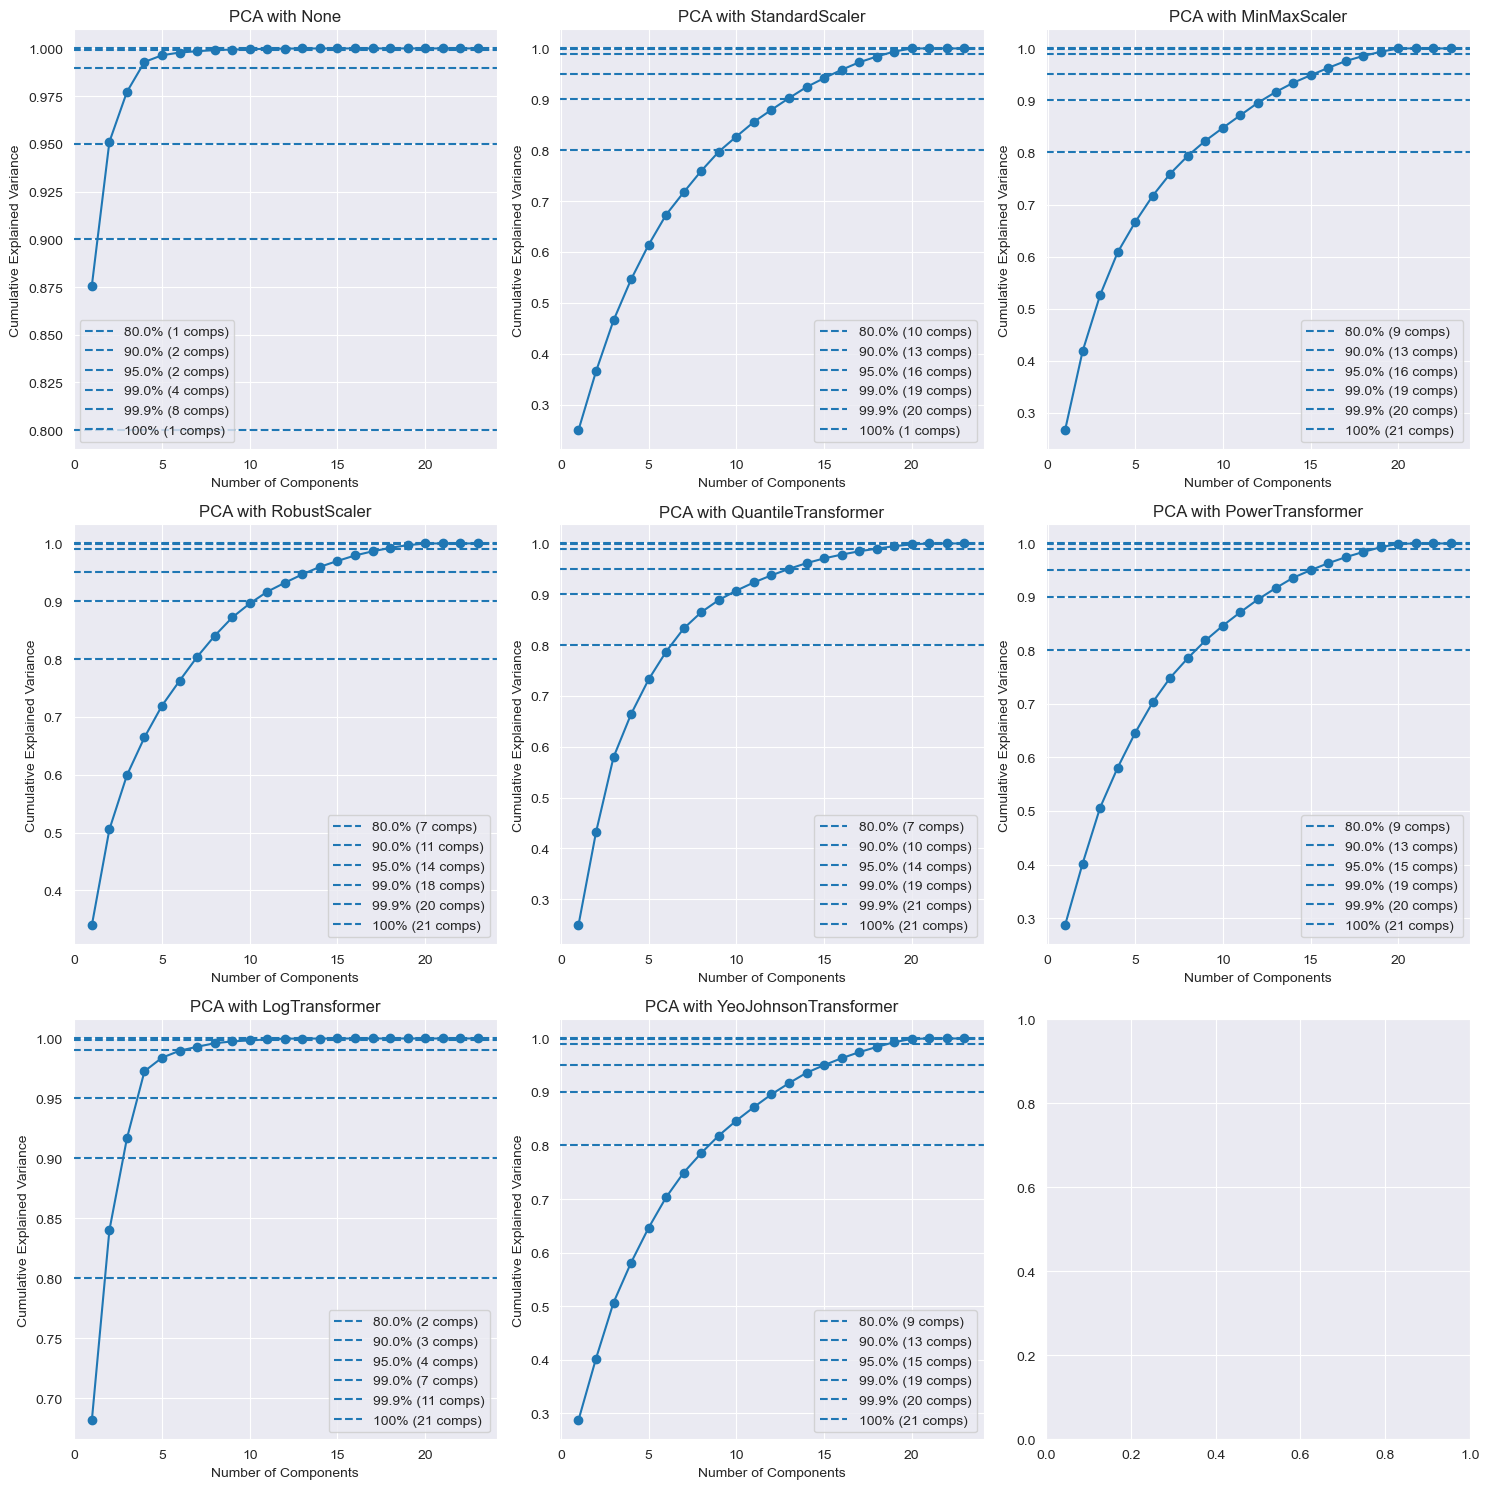

In [351]:
# Define scalers
scalers = {
    'None': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'QuantileTransformer': QuantileTransformer(n_quantiles=len(df), output_distribution='normal'),
    'PowerTransformer': PowerTransformer(),
    'LogTransformer': FunctionTransformer(np.log1p, validate=True),
    'YeoJohnsonTransformer': PowerTransformer(method='yeo-johnson', standardize=True)
}

# Placeholder for results
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 15))
axes = axes.flatten()

for i, (scaler_name, scaler) in enumerate(scalers.items()):
    # Create pipeline
    pipeline = Pipeline([
        ('scaler', scaler),
        ('pca', PCA())
    ]) if scaler is not None else Pipeline([('pca', PCA())])

    # Fit and transform data
    pipeline.fit(df)
    exp_var_ratio = np.cumsum(pipeline.named_steps['pca'].explained_variance_ratio_)

    # Plotting
    axes[i].plot(range(1, len(exp_var_ratio) + 1), exp_var_ratio, marker='o')
    axes[i].set_title(f'PCA with {scaler_name}')
    axes[i].set_xlabel('Number of Components')
    axes[i].set_ylabel('Cumulative Explained Variance')

    # Add horizontal lines for thresholds
    for threshold in [0.8, 0.9, 0.95, 0.99, 0.999, 1]:
        n_components = np.argmax(exp_var_ratio >= threshold) + 1
        axes[i].axhline(y=threshold, linestyle='--', label=f'{threshold * 100}% ({n_components} comps)')
        axes[i].legend()

plt.tight_layout()
plt.show()

[0.6816183  0.84011153 0.91673924 0.97266006 0.98397486 0.98974007
 0.99309281 0.99603362 0.99753409 0.99841783 0.99923952 0.99985397
 0.99990663 0.9999485  0.99997862 0.99998671 0.99999255 0.99999609
 0.99999789 0.99999915 1.         1.         1.        ]


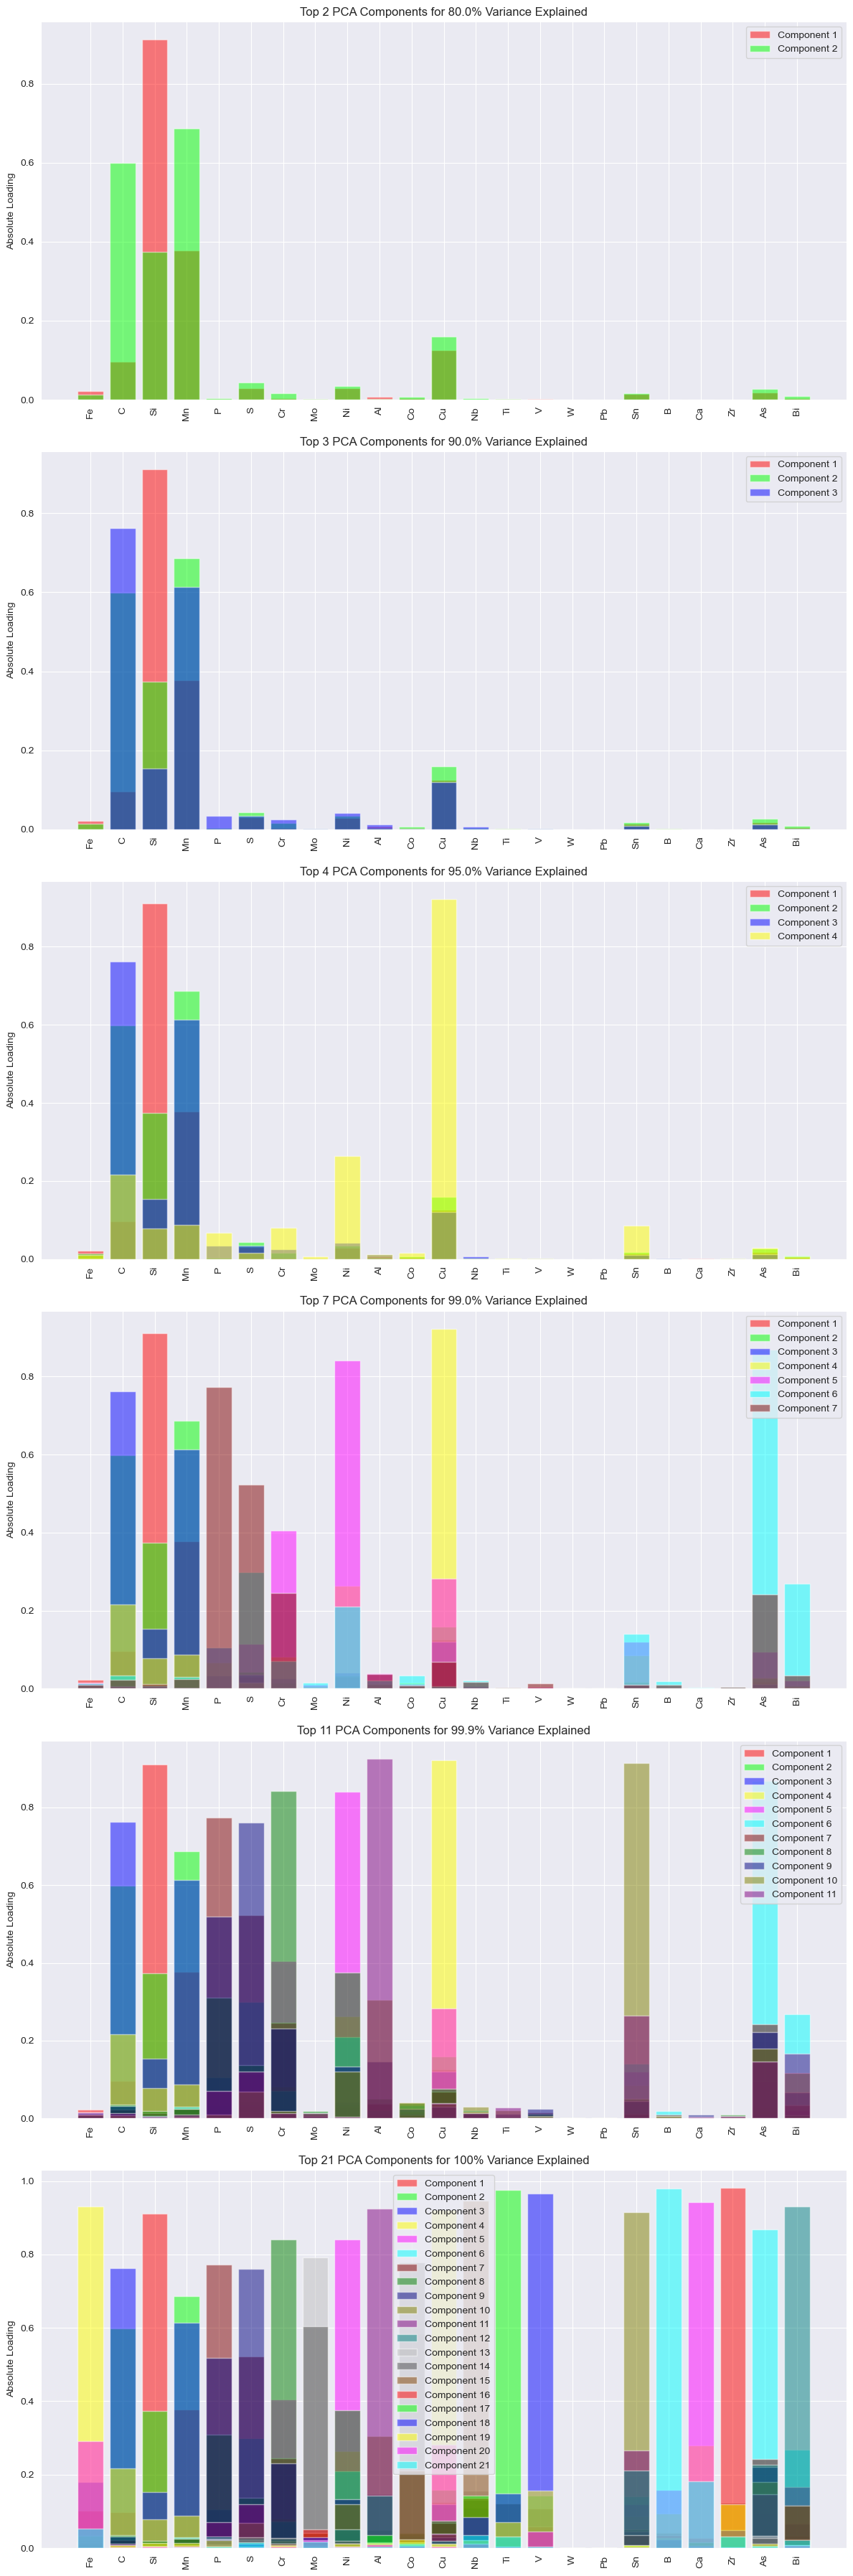

In [352]:
# Standardizing the Data using log1p transformation
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Fitting PCA
pca = PCA()
pca.fit(df_scaled)

# Calculating cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print(cumulative_variance)
# Finding the number of components for different levels of explained variance
thresholds = [0.80, 0.90, 0.95, 0.99, 0.999, 1]
n_components = [np.argmax(cumulative_variance >= t) + 1 for t in thresholds]

# Plotting
fig, ax = plt.subplots(len(thresholds), 1, figsize=(12, 6 * len(thresholds)))

# Colors for different components
colors = [
    (1.0, 0.0, 0.0),  # Red
    (0.0, 1.0, 0.0),  # Green
    (0.0, 0.0, 1.0),  # Blue
    (1.0, 1.0, 0.0),  # Yellow
    (1.0, 0.0, 1.0),  # Magenta
    (0.0, 1.0, 1.0),  # Cyan
    (0.5, 0.0, 0.0),  # Dark Red
    (0.0, 0.5, 0.0),  # Dark Green
    (0.0, 0.0, 0.5),  # Dark Blue
    (0.5, 0.5, 0.0),  # Olive
    (0.5, 0.0, 0.5),  # Purple
    (0.0, 0.5, 0.5),  # Teal
    (0.75, 0.75, 0.75),  # Light Grey
    (0.3, 0.3, 0.3),  # Dark Grey
    (0.5, 0.25, 0.0)  # Brown
]

for i, t in enumerate(thresholds):
    num_components = n_components[i]
    pca_components = pca.components_[:num_components]

    # Bar chart for each PCA component's absolute loadings
    for j in range(num_components):
        ax[i].bar(df.columns, np.abs(pca_components[j, :]), label=f'Component {j + 1}', color=colors[j % len(colors)],
                  alpha=0.5)

    ax[i].set_title(f'Top {num_components} PCA Components for {t * 100}% Variance Explained')
    ax[i].set_xticks(range(len(df.columns)))
    ax[i].set_xticklabels(df.columns, rotation=90)
    ax[i].set_ylabel('Absolute Loading')
    ax[i].legend()

plt.tight_layout()
plt.show()

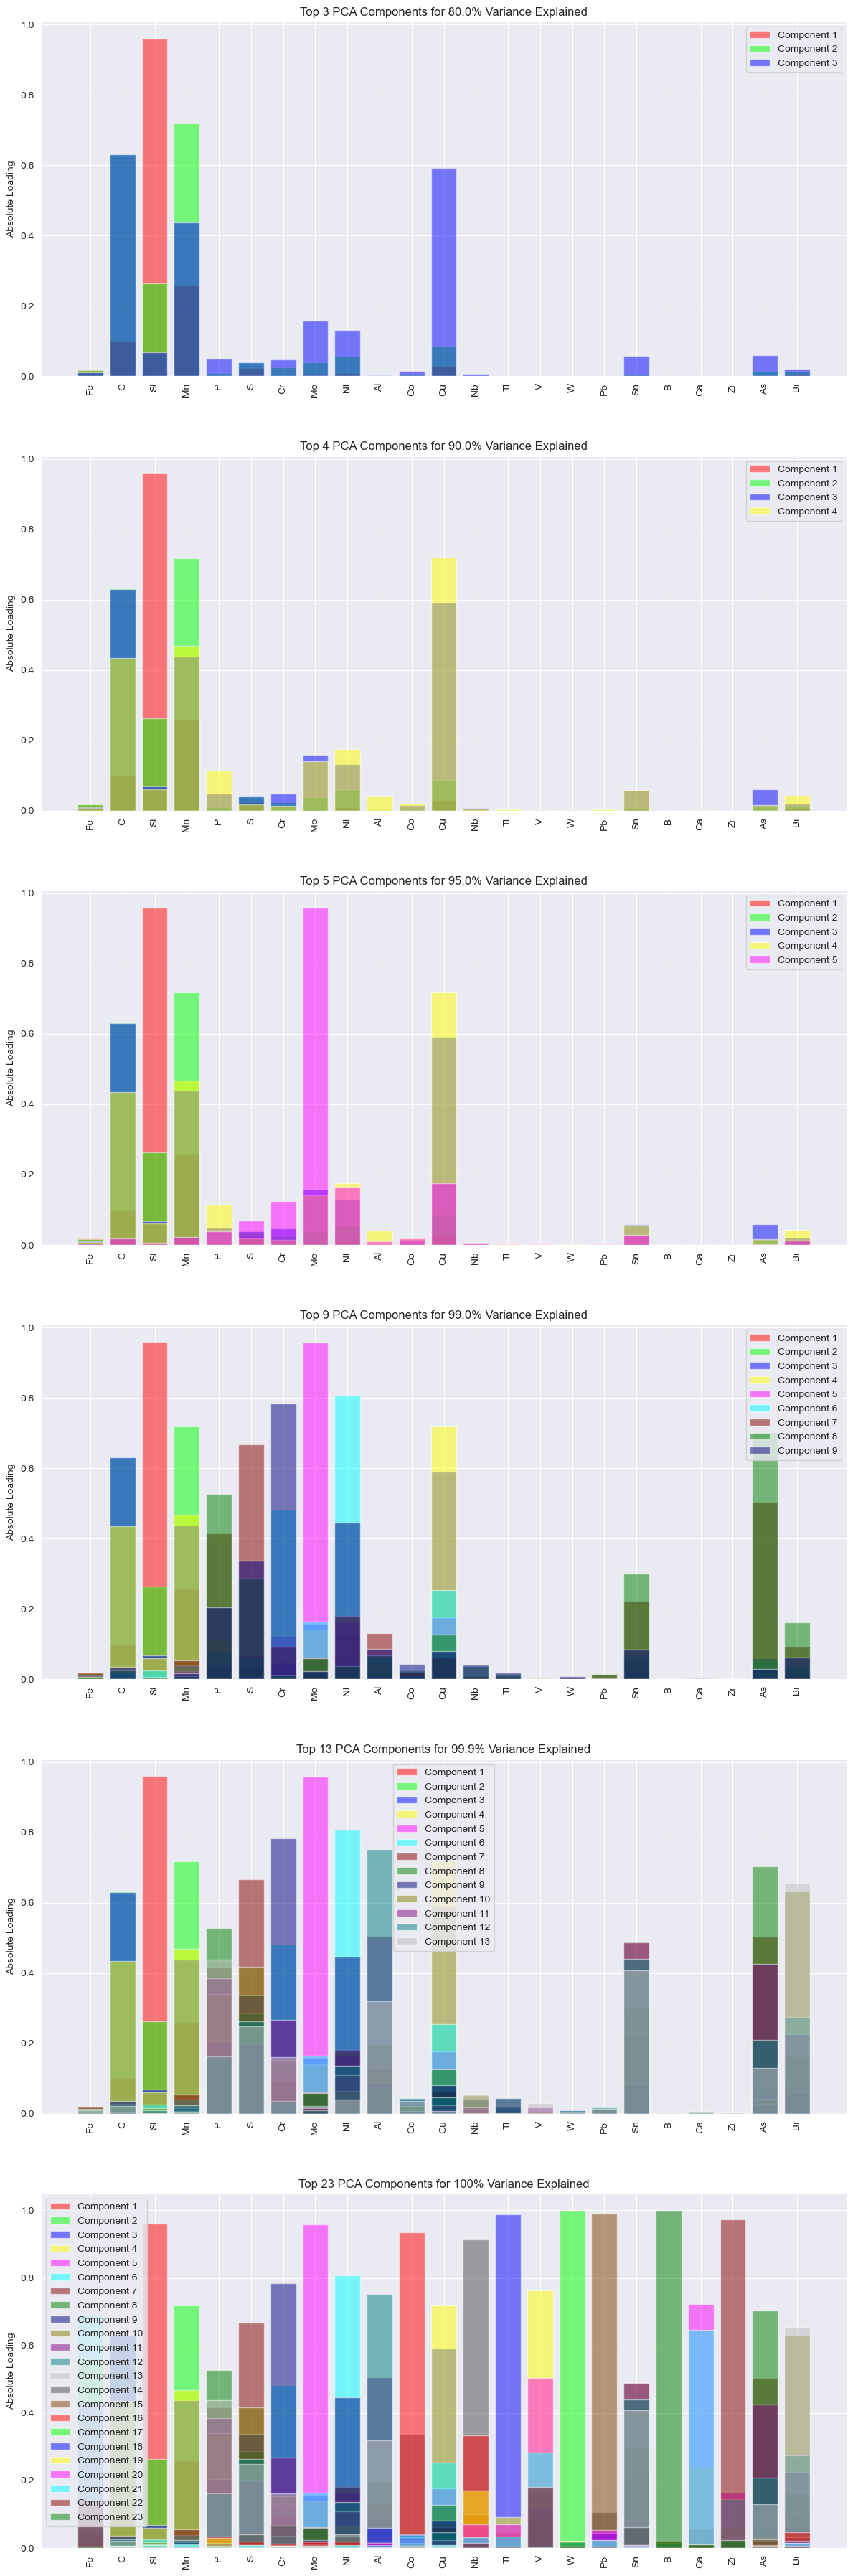

In [353]:
# Standardizing the Data using log1p transformation
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df_test1)

# Fitting PCA
pca = PCA()
pca.fit(df_scaled)

# Calculating cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Finding the number of components for different levels of explained variance
thresholds = [0.80, 0.90, 0.95, 0.99, 0.999, 1]
n_components = [np.argmax(cumulative_variance >= t) + 1 for t in thresholds]

# Plotting
fig, ax = plt.subplots(len(thresholds), 1, figsize=(12, 6 * len(thresholds)))

# Colors for different components
colors = [
    (1.0, 0.0, 0.0),  # Red
    (0.0, 1.0, 0.0),  # Green
    (0.0, 0.0, 1.0),  # Blue
    (1.0, 1.0, 0.0),  # Yellow
    (1.0, 0.0, 1.0),  # Magenta
    (0.0, 1.0, 1.0),  # Cyan
    (0.5, 0.0, 0.0),  # Dark Red
    (0.0, 0.5, 0.0),  # Dark Green
    (0.0, 0.0, 0.5),  # Dark Blue
    (0.5, 0.5, 0.0),  # Olive
    (0.5, 0.0, 0.5),  # Purple
    (0.0, 0.5, 0.5),  # Teal
    (0.75, 0.75, 0.75),  # Light Grey
    (0.3, 0.3, 0.3),  # Dark Grey
    (0.5, 0.25, 0.0)  # Brown
]

for i, t in enumerate(thresholds):
    num_components = n_components[i]
    pca_components = pca.components_[:num_components]

    # Bar chart for each PCA component's absolute loadings
    for j in range(num_components):
        ax[i].bar(df.columns, np.abs(pca_components[j, :]), label=f'Component {j + 1}', color=colors[j % len(colors)],
                  alpha=0.5)

    ax[i].set_title(f'Top {num_components} PCA Components for {t * 100}% Variance Explained')
    ax[i].set_xticks(range(len(df.columns)))
    ax[i].set_xticklabels(df.columns, rotation=90)
    ax[i].set_ylabel('Absolute Loading')
    ax[i].legend()

plt.tight_layout()
plt.show()

In [354]:
df_test

,Grade,ID 1,Fe,C,Si,Mn,P,S,Cr,Mo,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
0,20_21_1,St 48,98.7049,0.0331,0.204,0.701,0.0291,0.0295,0.0075,0.0051,...,0.0010,0.0020,0.04,0.0150,0.0080,0.001,0.0010,0.002,0.0507,0.0114
1,20_23_1,St 48,98.5637,0.1620,0.130,0.720,0.0217,0.0411,0.0052,0.0041,...,0.0032,0.0018,0.04,0.0347,0.0122,0.001,0.0013,0.002,0.0629,0.0108
2,20_28_1,St 48,98.5843,0.1440,0.265,0.600,0.0186,0.0261,0.0050,0.0049,...,0.0012,0.0018,0.04,0.0150,0.0191,0.001,0.0010,0.002,0.0638,0.0100
3,20_31_1,St 48,98.4618,0.2640,0.274,0.627,0.0129,0.0312,0.0050,0.0049,...,0.0012,0.0023,0.04,0.0150,0.0089,0.001,0.0010,0.002,0.0353,0.0100
4,20_32_1,St 48,98.4568,0.2550,0.288,0.643,0.0114,0.0577,0.0050,0.0040,...,0.0014,0.0023,0.04,0.0150,0.0106,0.001,0.0010,0.002,0.0444,0.0103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,S1_41_3_2,St 48-Th,98.9310,0.2370,0.005,0.553,0.0489,0.0401,0.0050,0.0044,...,0.0010,0.0022,0.04,0.0150,0.0023,0.001,0.0010,0.002,0.0071,0.0171
258,S2_11_1_2,St 48-BK?,98.9597,0.2250,0.005,0.429,0.0100,0.0305,0.0050,0.0042,...,0.0010,0.0015,0.04,0.0150,0.0081,0.001,0.0010,0.002,0.0311,0.0100
259,S2_11_2_2,St37-BK?,99.0097,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128
260,S2_11_2_2,St48-BK?,99.0097,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128


# K-Means Clustering
### Cluster Quality

In [355]:
# Auswählen der Spalten, die skaliert werden sollen
columns_to_scale = ['Fe', 'C', 'Si', 'Mn', 'P', 'S', 'Cr', 'Mo', 'Ni', 'Al', 'Co', 'Cu', 'Nb', 'Ti', 'V', 'W', 'Pb', 'Sn', 'B', 'Ca', 'Zr', 'As', 'Bi']

# Entferne Zeilen, bei denen in 'ID 1' ein '?' vorkommt
# df_test = df_test.loc[~df_test['ID 1'].str.contains('\?', na=False)]

# Skalieren der ausgewählten Spalten
scaler = FunctionTransformer(np.log1p, validate=True)
scaled_data = scaler.fit_transform(df_test[columns_to_scale])

# Erstellen eines neuen DataFrame für die skalierten Daten
df_scaled = pd.DataFrame(scaled_data, columns=columns_to_scale)

# K-Means-Clustering auf den skalierten Daten durchführen
# array mit den Werten 3 bis 12
k_range = np.arange(3, 12)

for i in k_range:
    kmeans = KMeans(n_clusters=i, random_state=0, n_init=10)
    cluster_labels = kmeans.fit_predict(df_scaled)

    # Hinzufügen des Cluster-Ergebnisses zum DataFrame
    df_test[f'Cluster_{i}'] = cluster_labels

# Erstellen einer Tabelle, die für jeden Wert in 'ID 1' die Cluster-Zugehörigkeit zeigt
for i in k_range:
    # Pivot-Tabelle erstellen
    pivot_table = pd.crosstab(df_test['ID 1'], df_test[f'Cluster_{i}'])

    # Ausgabe der Tabelle
    print(f"\nCluster-Verteilung für k={i}:")
    print(pivot_table)


Cluster-Verteilung für k=3:
Cluster_3     0    1  2
ID 1                   
St 37        23    0  0
St 48        39  173  0
St 48-BK      1    0  0
St 48-BK?     6    0  0
St 48-Th      6    0  0
St 48Th-BK?   2    0  0
St37-BK?      1    0  0
St48-BK?      1    1  0
StSi          0    0  9

Cluster-Verteilung für k=4:
Cluster_4     0   1  2    3
ID 1                       
St 37         1  22  0    0
St 48        57  14  0  141
St 48-BK      0   1  0    0
St 48-BK?     1   5  0    0
St 48-Th      0   6  0    0
St 48Th-BK?   0   2  0    0
St37-BK?      0   1  0    0
St48-BK?      0   1  0    1
StSi          0   0  9    0

Cluster-Verteilung für k=5:
Cluster_5      0   1   2  3   4
ID 1                           
St 37          0   1   1  0  21
St 48        143  17  52  0   0
St 48-BK       0   1   0  0   0
St 48-BK?      0   3   1  0   2
St 48-Th       0   6   0  0   0
St 48Th-BK?    0   2   0  0   0
St37-BK?       0   0   0  0   1
St48-BK?       1   0   0  0   1
StSi           0   0 

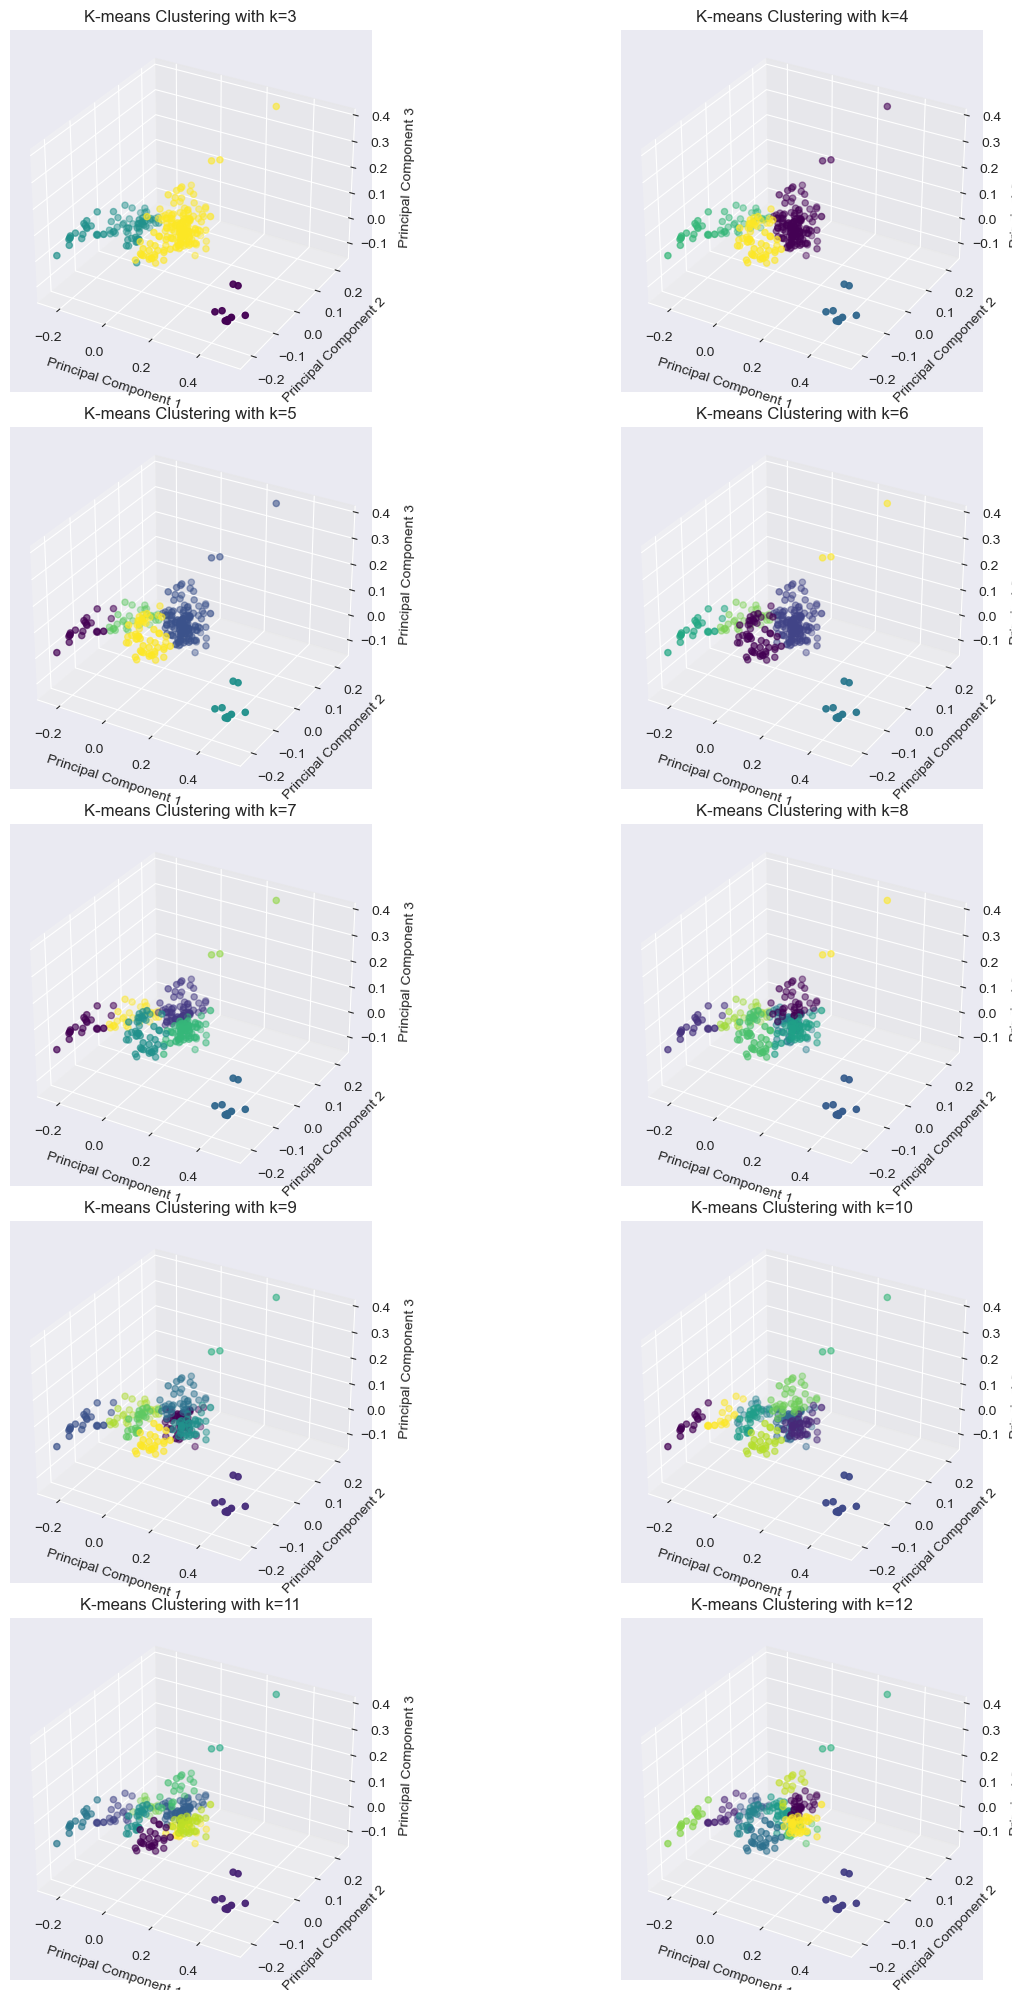

In [356]:
# Standardizing the Data
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df_test1)

# Applying PCA to reduce dimensions to 3
pca = PCA(n_components=3)
reduced_data = pca.fit_transform(df_scaled)

# Number of subplots
num_plots = 10  # for k from 3 to 12

# Create a figure with multiple subplots
fig = plt.figure(figsize=(15, 20))

for i, k in enumerate(range(3, 13)):
    # Applying K-means clustering
    kmeans = KMeans(n_clusters=k, n_init=10)
    clusters = kmeans.fit_predict(reduced_data)

    # Adding a 3D subplot for each k
    ax = fig.add_subplot(5, 2, i + 1, projection='3d')
    ax.scatter(reduced_data[:, 0], reduced_data[:, 1], reduced_data[:, 2], c=clusters, cmap='viridis', marker='o')

    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.set_zlabel('Principal Component 3')
    ax.set_title(f'K-means Clustering with k={k}')

plt.tight_layout()
plt.show()

          C        Si        Mn         P         S        Cr        Ni  \
0  0.289667  0.204833  0.530167  0.024883  0.044583  0.034917  0.049383   
1  0.097283  0.975000  0.674667  0.026433  0.034617  0.009183  0.042583   
2  0.132667  0.834167  0.899667  0.014850  0.047567  0.023467  0.112167   
3  0.125333  0.792167  0.959333  0.014950  0.046583  0.029950  0.112667   
4  0.235143  0.238571  0.729143  0.027686  0.042086  0.014886  0.049871   

         Al        Cu  
0  0.002083  0.144333  
1  0.003133  0.198000  
2  0.054733  0.365667  
3  0.050267  0.367000  
4  0.004214  0.166571  


/Users/joshuakuhwald/anaconda3/lib/python3.11/site-packages/sklearn/base.py:457: UserWarning:

X has feature names, but FunctionTransformer was fitted without feature names



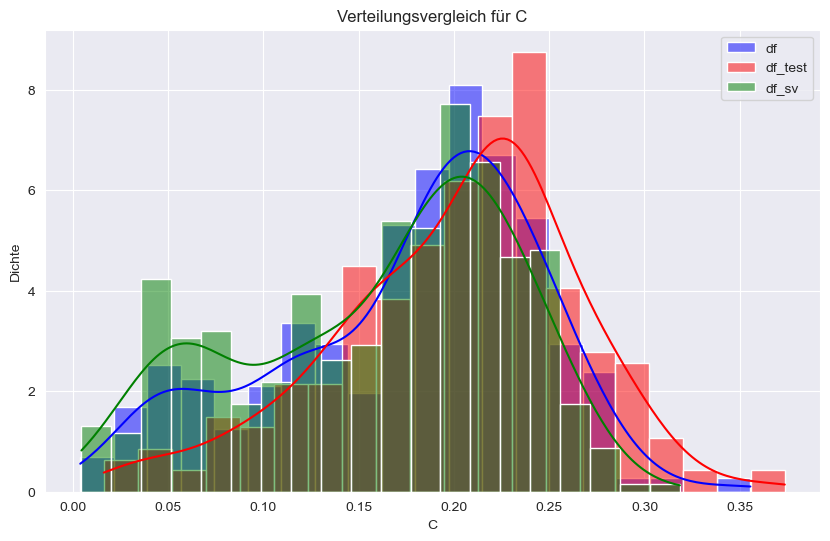

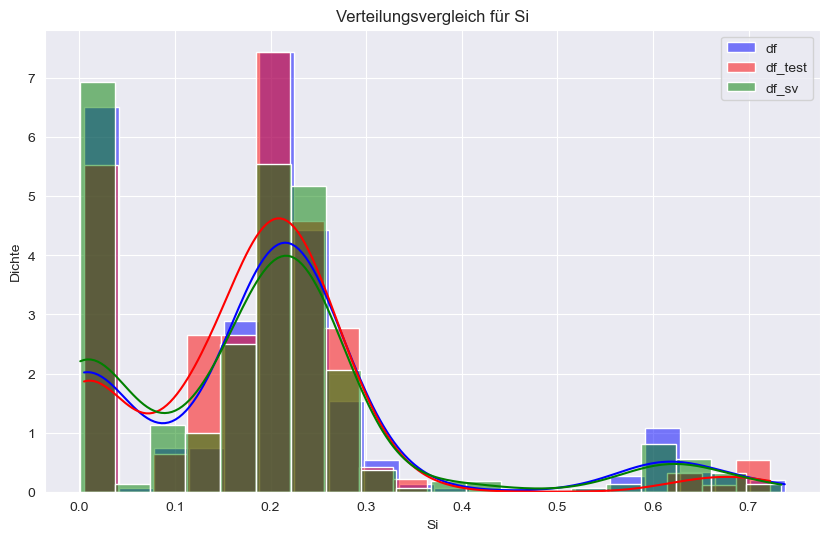

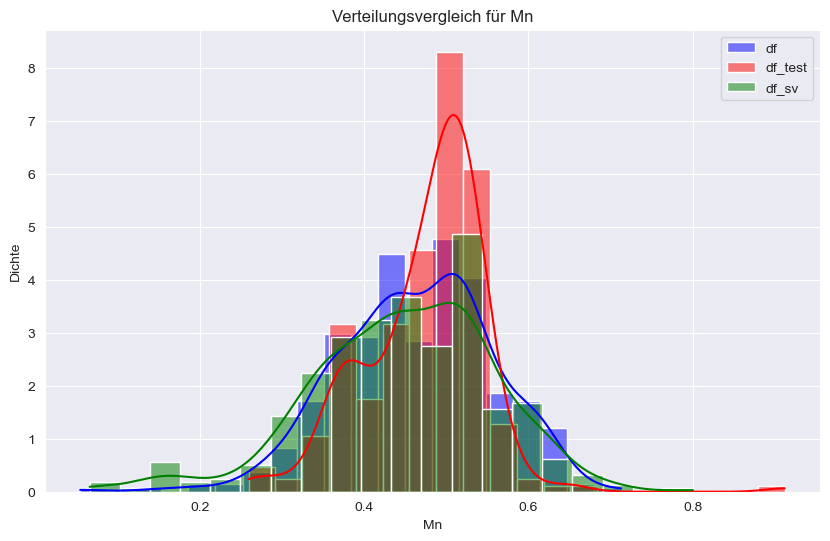

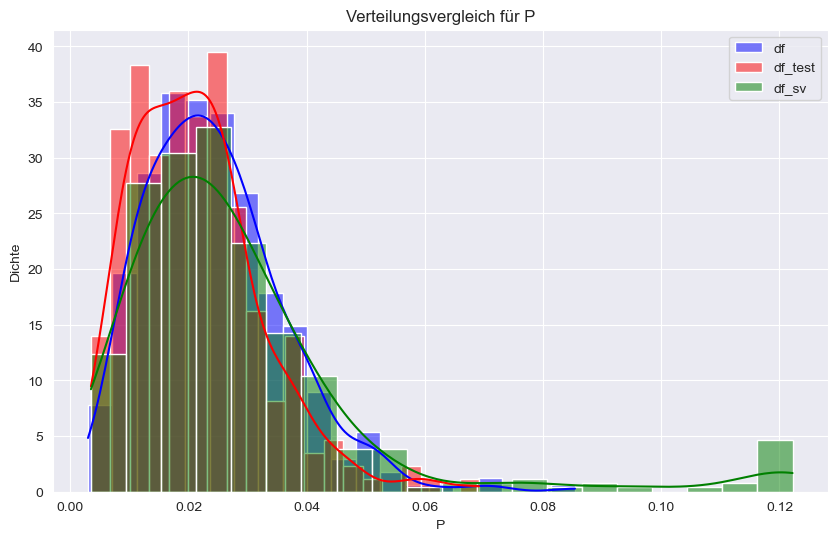

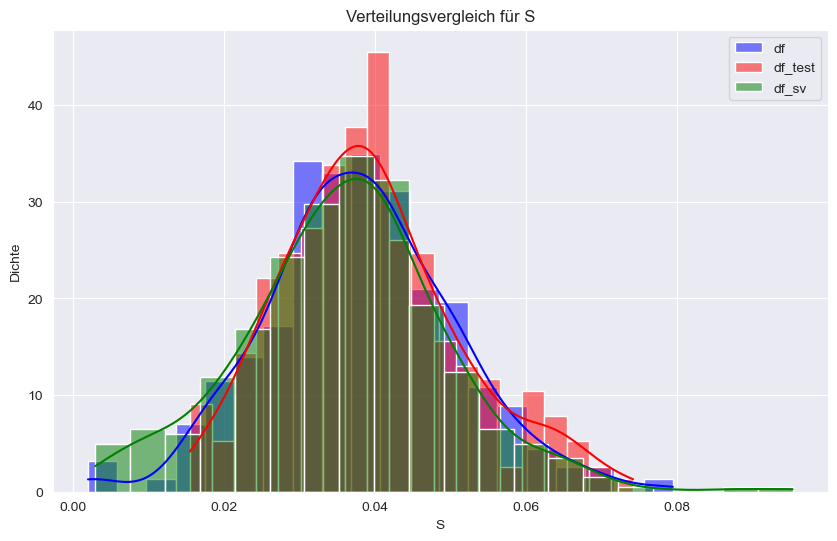

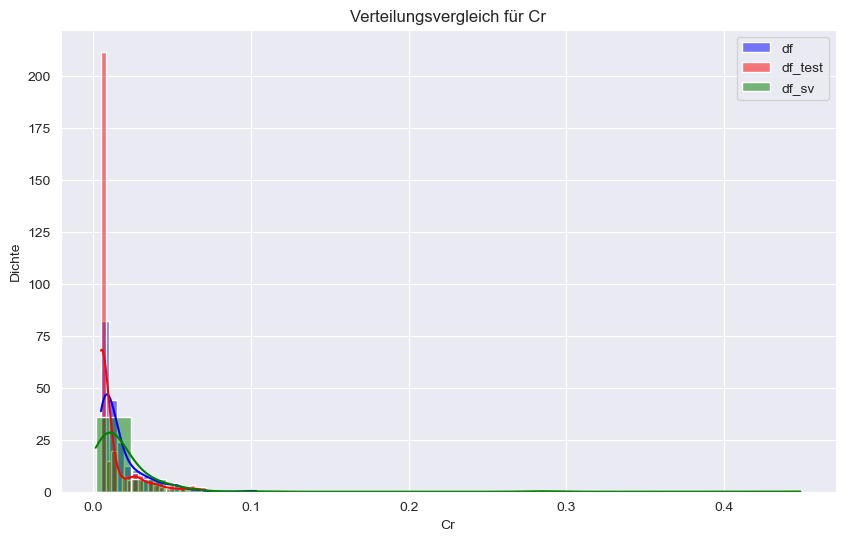

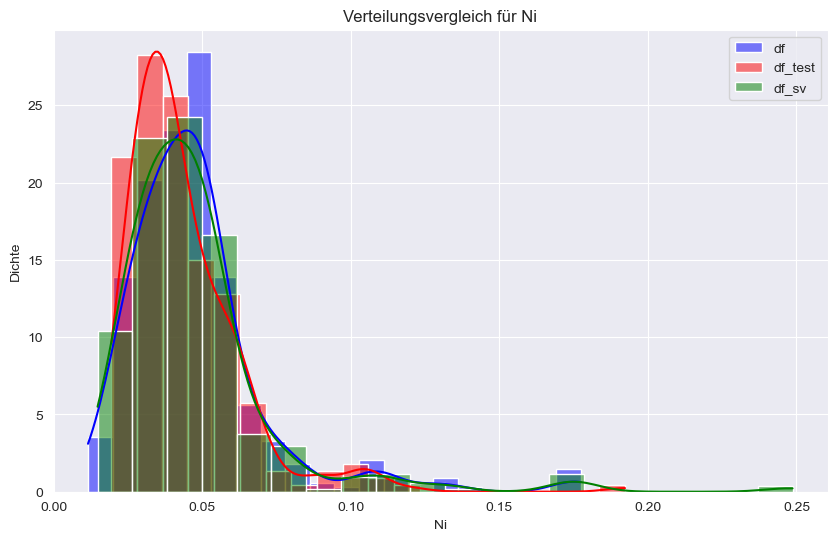

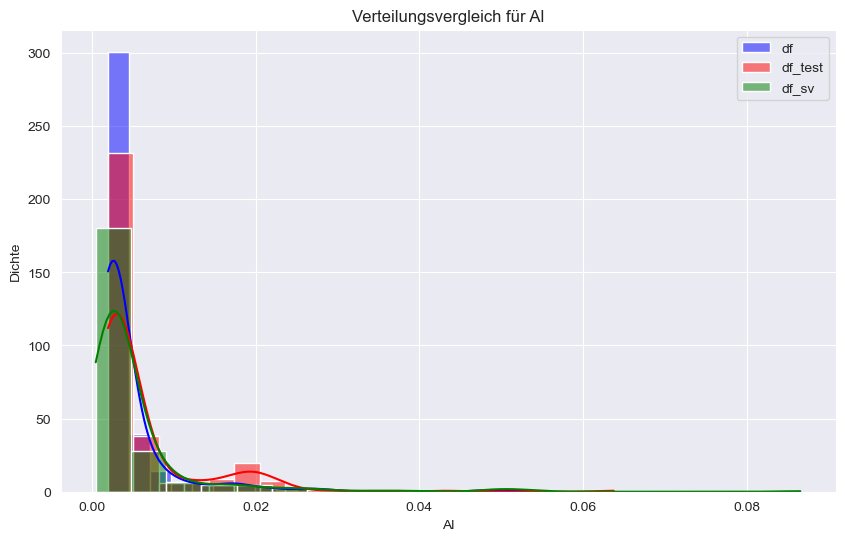

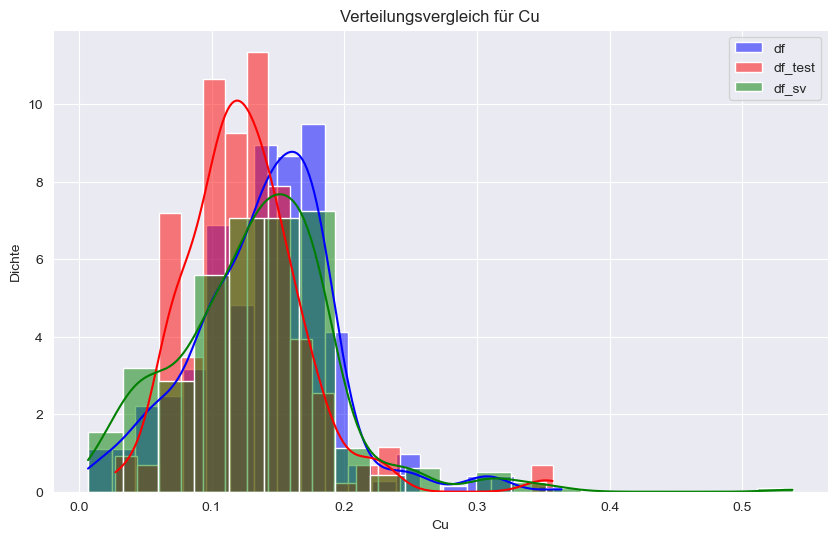

In [357]:
# read in the data from csv file
df_sv = pd.read_csv('data/cleaned data/labeled_OES_data.csv')
df_sv = df_sv.drop(columns=['steel_class'])
df_sv = df_sv.apply(lambda x: x.str.replace(',', '.').astype(float) if x.name != 'Material' else x)
print(df_sv.head())

# Standardizing the Data using log1p transformation
scaler = FunctionTransformer(np.log1p, validate=True)
df_sv_scaled_array = scaler.transform(df_sv)
df_scaled_array = scaler.fit_transform(df)
df_test1_scaled_array = scaler.transform(df_test1)


# Umwandlung der skalierten Arrays zurück in DataFrames
df_scaled = pd.DataFrame(df_scaled_array, columns=df.columns)
df_test1_scaled = pd.DataFrame(df_test1_scaled_array, columns=df_test1.columns)
df_sv_scaled = pd.DataFrame(df_sv_scaled_array, columns=df_sv.columns)

# Spalten die verglichen werden sollen
columns_to_compare = ['C','Si','Mn','P','S','Cr','Ni','Al','Cu']

# Erstellen der Diagramme für jede Spalte
for column in columns_to_compare:
    plt.figure(figsize=(10, 6))

    # Histogramm für df
    sns.histplot(df_scaled[column], color="blue", label='df', kde=True, stat="density", bins=20)

    # Histogramm für df_test
    sns.histplot(df_test1_scaled[column], color="red", label='df_test', kde=True, stat="density", bins=20)
    
    # Histogramm für df_sv
    sns.histplot(df_sv_scaled[column], color="green", label='df_sv', kde=True, stat="density", bins=20)

    # Legende und Titel hinzufügen
    plt.legend()
    plt.title(f'Verteilungsvergleich für {column}')
    plt.xlabel(column)
    plt.ylabel('Dichte')

    # Diagramm anzeigen
    plt.show()


Cluster-Verteilung für k=3:
Cluster_3     0    1   2
steel_class             
Flussstahl    9    0   0
Puddelstahl  25    1   0
St 37        95    2   0
St 48         8  262   4
St Si         0    0  31

Cluster-Verteilung für k=4:
Cluster_4     0    1   2   3
steel_class                 
Flussstahl    0    0   0   9
Puddelstahl  25    1   0   0
St 37         1    3   0  93
St 48         1  258   4  11
St Si         0    0  31   0

Cluster-Verteilung für k=5:
Cluster_5     0    1   2   3    4
steel_class                      
Flussstahl    0    0   9   0    0
Puddelstahl  24    2   0   0    0
St 37         0    1  95   0    1
St 48         0  107  10   4  153
St Si         0    0   0  31    0

Cluster-Verteilung für k=6:
Cluster_6     0    1   2    3   4  5
steel_class                         
Flussstahl    0    0   9    0   0  0
Puddelstahl   0    0   0    2  24  0
St 37         0    1  94    2   0  0
St 48         1  148   9  112   0  4
St Si        31    0   0    0   0  0

Cluster-

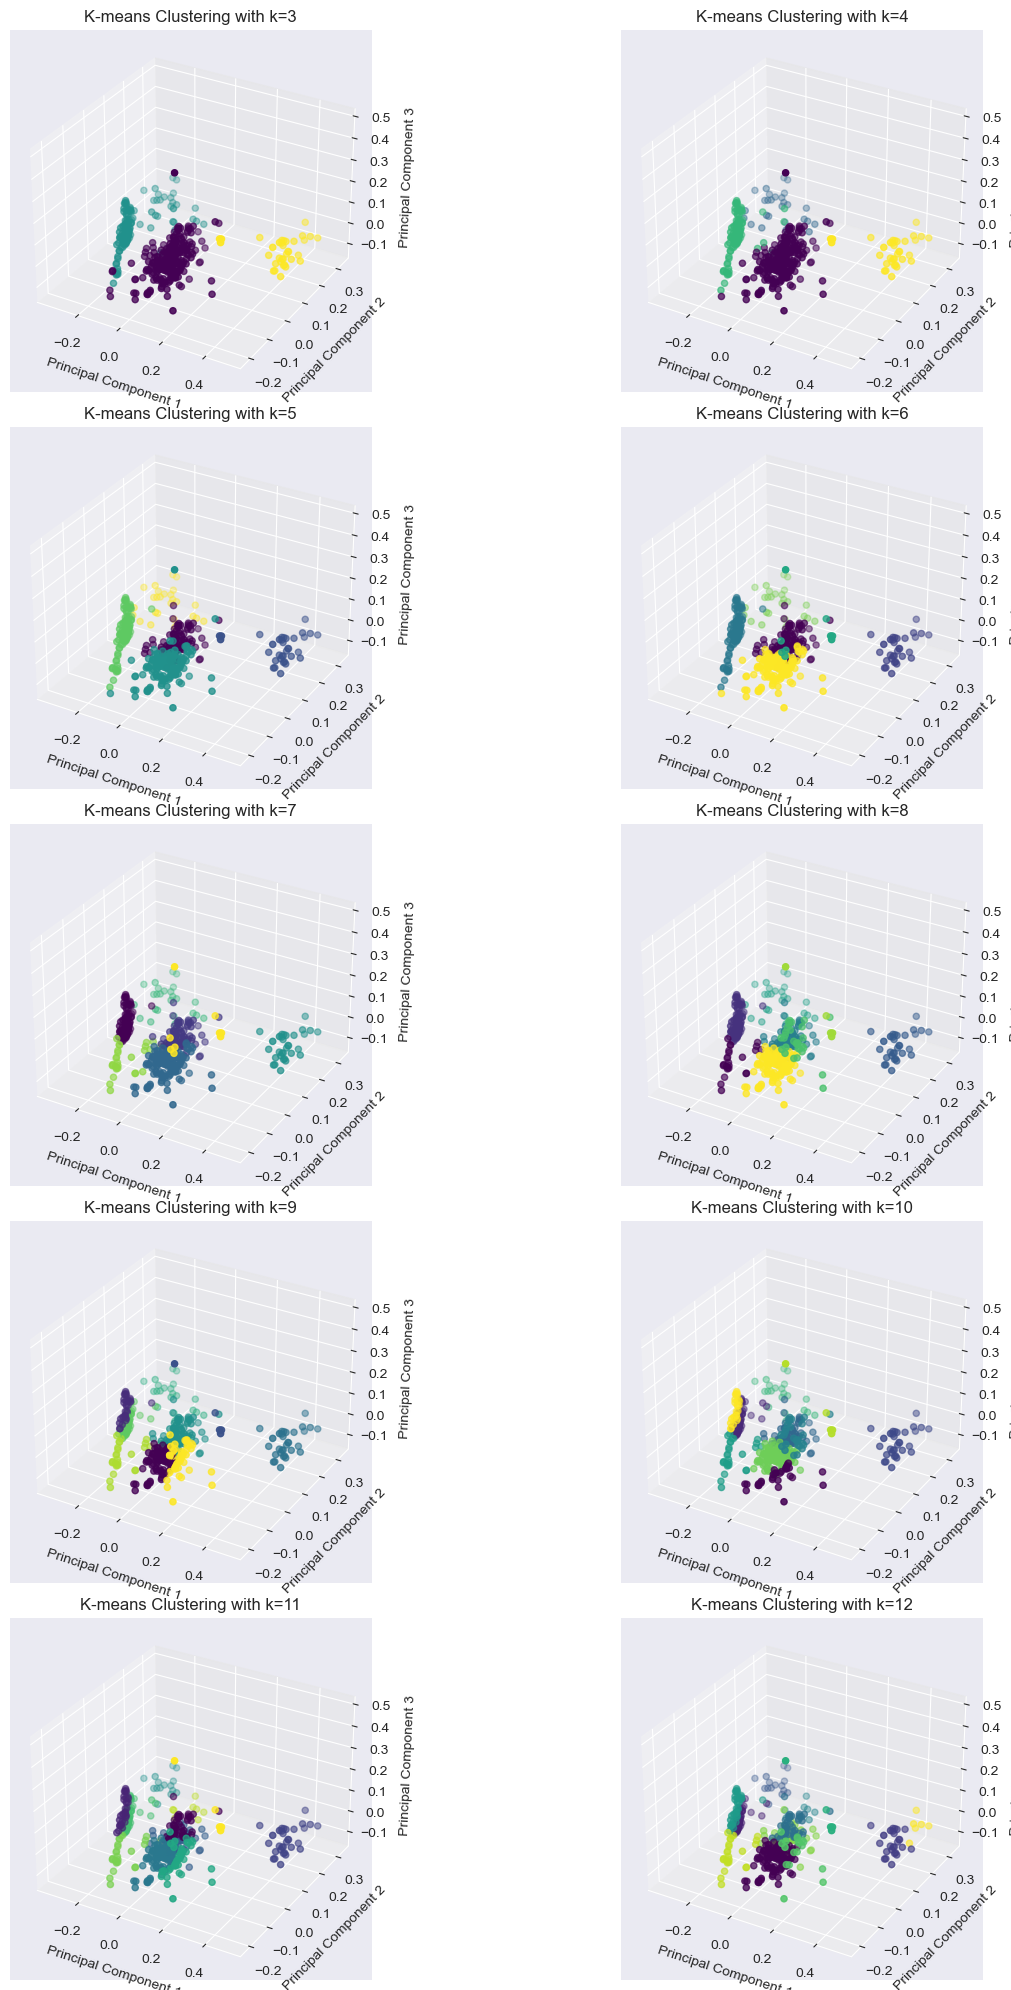

In [358]:
df_sv = pd.read_csv('data/cleaned data/labeled_OES_data.csv')
df_sv = df_sv.apply(lambda x: x.str.replace(',', '.').astype(float) if x.name != 'steel_class' else x)

# save df_sv to csv
df_sv.to_csv('data/cleaned data/labeled_OES_data_proper.csv', index=False)

# Auswählen der Spalten, die skaliert werden sollen
columns_to_scale = ['C','Si','Mn','P','S','Cr','Ni','Al','Cu']

# Skalieren der ausgewählten Spalten
scaler = FunctionTransformer(np.log1p, validate=True)
scaled_data = scaler.fit_transform(df_sv[columns_to_scale])

# Erstellen eines neuen DataFrame für die skalierten Daten
df_scaled = pd.DataFrame(scaled_data, columns=columns_to_scale)

# K-Means-Clustering auf den skalierten Daten durchführen
# array mit den Werten 3 bis 12
k_range = np.arange(3, 12)

for i in k_range:
    kmeans = KMeans(n_clusters=i, random_state=0, n_init=10)
    cluster_labels = kmeans.fit_predict(df_scaled)

    # Hinzufügen des Cluster-Ergebnisses zum DataFrame
    df_sv[f'Cluster_{i}'] = cluster_labels

# Erstellen einer Tabelle, die für jeden Wert in 'ID 1' die Cluster-Zugehörigkeit zeigt
for i in k_range:
    # Pivot-Tabelle erstellen
    pivot_table = pd.crosstab(df_sv['steel_class'], df_sv[f'Cluster_{i}'])

    # Ausgabe der Tabelle
    print(f"\nCluster-Verteilung für k={i}:")
    print(pivot_table)
    
# Applying PCA to reduce dimensions to 3
pca = PCA(n_components=3)
reduced_data = pca.fit_transform(df_scaled)

# Number of subplots
num_plots = 10  # for k from 3 to 12

# Create a figure with multiple subplots
fig = plt.figure(figsize=(15, 20))

for i, k in enumerate(range(3, 13)):
    # Applying K-means clustering
    kmeans = KMeans(n_clusters=k, n_init=10)
    clusters = kmeans.fit_predict(reduced_data)

    # Adding a 3D subplot for each k
    ax = fig.add_subplot(5, 2, i + 1, projection='3d')
    ax.scatter(reduced_data[:, 0], reduced_data[:, 1], reduced_data[:, 2], c=clusters, cmap='viridis', marker='o')

    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.set_zlabel('Principal Component 3')
    ax.set_title(f'K-means Clustering with k={k}')

plt.tight_layout()
plt.show()

In [359]:
# apply PCA to reduce dimensions to 3
pca = PCA()
reduced_data = pca.fit_transform(df_scaled)

# calculate the cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print(cumulative_variance)

[0.64565058 0.8305291  0.90017481 0.96262414 0.97857    0.9890954
 0.99631542 0.9988233  1.        ]
